# CivicAI - 02 Feature selection

This notebook decides **which columns the model is allowed to use**, and checks the pipeline that turns a raw request into numbers.

1. The target
2. The chronological split
3. Candidate features and excluded columns
4. The preprocessing pipeline
5. Training-serving check
6. Feature selection: mutual information, importance, redundancy, drop-one-group test
7. Final feature list

**Rules followed here**

- Every measurement of "how useful is this feature" uses the **training split**. The validation split is used only to score quick models. The **test split is not opened** in this notebook.
- The quick XGBoost model used below is a measuring tool for feature selection. It is not tuned and it is not the final model. Models are compared properly in Phase 5.

## 1. The target

**`resolved_within_7d`** is what the model predicts.

- It is **1** if the request was closed 7 days (168 hours) or less after it was created, and **0** if it took longer.
- It is computed as `closed_date - created_date`, in `src/preprocessing.py` (`add_target`).
- The 7-day threshold was checked in notebook 01 and confirmed by the student. In the training period about 83% of requests are class 1 and 17% are class 0.

**Why this target.** When someone files a 311 request, a useful answer is "will this be dealt with within a week?". It is a yes/no question that is easy to explain, and the city records the two dates needed to answer it for past requests.

**What must not be used to predict it.** `closed_date` and `duration_hours` *are* the answer, and `status` and `resolution_description` are only written after the request is handled. A model given these would look perfect and be useless, because none of them exist at the moment a new request is filed. They are on an explicit excluded list (section 3).

**A limit to remember.** "Closed" means the agency closed the request in its system. It does not always mean the problem was physically fixed.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, mutual_info_score, roc_auc_score
from xgboost import XGBClassifier

sys.path.insert(0, "..")                 # so that "src" can be imported from the notebooks folder
from src import features as ft
from src import preprocessing as pp

SEED = 42
DATA_DIR = Path("../data/processed")
FIG_DIR = Path("../reports/figures")

BLUE, GREY, INK, ORANGE = "#2a78d6", "#c3c2b7", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})

## 2. The chronological split

The 198,867 cleaned rows are sorted by `created_date` and cut by time: the **oldest 70%** is the training split, the **next 15%** is validation and the **newest 15%** is the test split (`ft.chronological_split`).

**Why by time and not at random.** The model will be used on requests filed *after* it was trained. A random split would let it learn from requests filed later than the ones it is tested on, which makes the scores look better than they will be in real use. Splitting by time gives an honest picture.

In [2]:
clean = pd.read_parquet(DATA_DIR / "clean.parquet")
train, val, test = ft.chronological_split(clean)
splits = {"train": train, "val": val, "test": test}
for name, part in splits.items():
    part.to_parquet(DATA_DIR / f"{name}.parquet", index=False)

display(ft.describe_splits(splits).style.format({"rows": "{:,}", "share_of_rows": "{:.1%}", "share_resolved_within_7d": "{:.1%}"}))
assert train["created_date"].max() <= val["created_date"].min() <= val["created_date"].max() <= test["created_date"].min()
print("No overlap in time: every training request is older than every validation request, and so on.")

y_train, y_val = train[ft.TARGET], val[ft.TARGET]
del test          # the test split is not used again in this notebook

,rows,share_of_rows,from,to,share_resolved_within_7d
split,,,,,
train,"139,206",70.0%,2024-01-01 00:00:00,2025-12-02 20:45:49,82.8%
val,"29,830",15.0%,2025-12-02 20:48:18,2026-04-14 21:10:06,83.2%
test,"29,831",15.0%,2026-04-14 21:11:23,2026-08-31 23:59:06,81.7%


No overlap in time: every training request is older than every validation request, and so on.


The share resolved within 7 days is similar in all three splits, so the model is trained and judged on the same kind of problem.

## 3. Candidate features and excluded columns

**Candidates (15).** Eleven columns from the cleaned file, plus four made from `created_date` by `ft.add_time_features`:

- `hour` (0-23), `weekday` (0 = Monday), `month` (1-12), `is_weekend` (1 = Saturday or Sunday).

**Excluded.** The list `ft.EXCLUDED_COLUMNS` names every column that must never be a model input. `ft.assert_no_excluded` stops with an error if one of them appears among the inputs. The check runs every time a pipeline is built and every time it transforms data.

The year is excluded on purpose: a model that learned "2025 was faster than 2024" would have learned about the past, not about requests.

In [3]:
print("Candidate features:")
print("  text      :", ft.CATEGORICAL_CANDIDATES)
print("  location  :", ft.COORDINATE_FEATURES)
print("  time      :", ft.TIME_FEATURES)
print("\nExcluded columns:", ft.EXCLUDED_COLUMNS)

ft.assert_no_excluded(ft.CANDIDATE_FEATURES)
print("\nassert passed: no excluded column is among the candidates")

try:        # show that the check really stops a leak
    ft.assert_no_excluded(ft.CANDIDATE_FEATURES + ["duration_hours"])
except AssertionError as error:
    print("assert correctly refuses a leaking column ->", error)

Candidate features:
  text      : ['complaint_type', 'descriptor', 'location_type', 'borough', 'incident_zip', 'open_data_channel_type', 'agency', 'address_type', 'community_board']
  location  : ['latitude', 'longitude']
  time      : ['hour', 'weekday', 'month', 'is_weekend']

Excluded columns: ['unique_key', 'created_date', 'created_at', 'year', 'duration_hours', 'resolved_within_7d', 'closed_date', 'status', 'resolution_description', 'resolution_action_updated_date', 'due_date']

assert passed: no excluded column is among the candidates
assert correctly refuses a leaking column -> excluded columns reached the model: ['duration_hours']


## 4. The preprocessing pipeline

One scikit-learn `Pipeline` (`ft.build_pipeline`) does everything between a raw request and the model:

| Step | What it is | What it does |
| --- | --- | --- |
| `clean` | `ft.RequestCleaner` | Takes the raw request fields, exactly as the API receives them. Applies the notebook 01 cleaning rules (`pp.clean_features`), replaces rare or unseen categories with "Other", adds the four time features, and returns **only** the feature columns. |
| `encode` | `ColumnTransformer` | Text columns: `OneHotEncoder(handle_unknown="ignore")`, one 0/1 column per category, stored sparsely. Latitude and longitude: fill missing values with the training median, add a 0/1 "was missing" column, then `StandardScaler`. Time features: `StandardScaler`. |
| `model` | added in Phase 5 | |

**Fitted on the training split only.** The list of common categories, the one-hot columns, the median coordinates and the scaling values are all learned from training rows. Validation, test and API requests are only *transformed*.

In [4]:
all_features = ft.build_pipeline(features=ft.CANDIDATE_FEATURES)        # no model yet
X_train_all = all_features.fit_transform(train[ft.RAW_INPUT_COLUMNS])   # fit on TRAIN only
X_val_all = all_features.transform(val[ft.RAW_INPUT_COLUMNS])
display(all_features)

print("Raw input columns:", ft.RAW_INPUT_COLUMNS)
print(f"\nOutput with all 15 candidates: train {X_train_all.shape}, validation {X_val_all.shape}")
print(f"Stored as: {type(X_train_all).__name__} (sparse), {X_train_all.nnz / np.prod(X_train_all.shape):.1%} of cells are non-zero")

saved = pp.load_cleaning_values("../models/cleaning_values.json")
learned = all_features["clean"].values_["kept_categories"]
for column, kept_list in saved["kept_categories"].items():
    # "Other" is the group label itself, so it is ignored in the comparison
    assert set(learned[column]) - {pp.OTHER} == set(kept_list) - {pp.OTHER}, column
print("\nThe category lists learned by the pipeline equal models/cleaning_values.json from notebook 01.")

,steps,"[('clean', ...), ('encode', ...)]"
,transform_input,None
,memory,None
,verbose,False
,features,"['complaint_type', 'descriptor', ...]"
,transformers,"[('cat', ...), ('coord', ...), ...]"
,remainder,'drop'
,sparse_threshold,1.0
,n_jobs,None
,transformer_weights,None
,verbose,False


Raw input columns: ['complaint_type', 'descriptor', 'location_type', 'borough', 'incident_zip', 'open_data_channel_type', 'agency', 'address_type', 'community_board', 'latitude', 'longitude', 'created_date']

Output with all 15 candidates: train (139206, 650), validation (29830, 650)
Stored as: csr_matrix (sparse), 2.6% of cells are non-zero

The category lists learned by the pipeline equal models/cleaning_values.json from notebook 01.


## 5. Training-serving check

**The risk.** The model is trained on the cleaned file, but the API will receive raw, uncleaned fields. If the two paths clean data even slightly differently, the model sees one kind of input in training and another in real use, and its predictions quietly get worse. This is called *training-serving skew*.

**Check 1.** Take 5,000 random training rows. Fetch the same rows from the **raw** file (all 44 untouched text columns) and run only the pipeline's `clean` step on them. The result must equal the values in `clean.parquet`, column by column.

**Check 2.** Run the `clean` step on rows that are *already* clean. Nothing may change.

In [5]:
cleaner = all_features["clean"]
sample = train.sample(5000, random_state=SEED)
expected = ft.add_time_features(sample)[ft.CANDIDATE_FEATURES].reset_index(drop=True)

raw = pd.read_parquet("../data/raw/nyc311_raw.parquet")
raw_rows = raw.set_index("unique_key").loc[sample["unique_key"]].reset_index()     # same rows, raw values
print(f"Raw rows fetched: {raw_rows.shape[0]:,} rows, {raw_rows.shape[1]} raw columns (all text)")

def compare(result, label):
    result = result.reset_index(drop=True)
    same = {c: int(((result[c] == expected[c]) | (result[c].isna() & expected[c].isna())).sum()) for c in expected.columns}
    return pd.Series(same, name=label)

checks = pd.concat([compare(cleaner.transform(raw_rows), "equal_from_raw"),
                    compare(cleaner.transform(sample), "equal_from_clean")], axis=1)
checks.insert(0, "rows_compared", len(sample))
display(checks.style.format("{:,}"))

assert (checks["equal_from_raw"] == len(sample)).all() and (checks["equal_from_clean"] == len(sample)).all()
print("PASS: the pipeline's cleaning step reproduces clean.parquet exactly, from raw rows and from clean rows.")
print("Columns returned by the cleaning step:", list(cleaner.transform(raw_rows).columns))

Raw rows fetched: 5,000 rows, 44 raw columns (all text)


,rows_compared,equal_from_raw,equal_from_clean
complaint_type,"5,000","5,000","5,000"
descriptor,"5,000","5,000","5,000"
location_type,"5,000","5,000","5,000"
borough,"5,000","5,000","5,000"
incident_zip,"5,000","5,000","5,000"
open_data_channel_type,"5,000","5,000","5,000"
agency,"5,000","5,000","5,000"
address_type,"5,000","5,000","5,000"
community_board,"5,000","5,000","5,000"
latitude,"5,000","5,000","5,000"


PASS: the pipeline's cleaning step reproduces clean.parquet exactly, from raw rows and from clean rows.
Columns returned by the cleaning step: ['complaint_type', 'descriptor', 'location_type', 'borough', 'incident_zip', 'open_data_channel_type', 'agency', 'address_type', 'community_board', 'latitude', 'longitude', 'hour', 'weekday', 'month', 'is_weekend']


**Check 3 - awkward input must not crash.** Five made-up requests, the kind the API will get:

1. a normal request, but typed in lower case with extra spaces and using the API's field name `created_at`;
2. a complaint type and descriptor the model has never seen;
3. no coordinates and no ZIP code;
4. coordinates outside New York and an invalid ZIP code;
5. only the four required fields.

In [6]:
odd = pd.DataFrame([
    {"complaint_type": "  noise -   residential ", "descriptor": "loud music/party", "borough": "brooklyn",
     "location_type": "Residential Building/House", "open_data_channel_type": "phone", "incident_zip": "11201",
     "latitude": 40.69, "longitude": -73.99, "created_at": "2026-11-09T22:15:00"},
    {"complaint_type": "Drone Delivery Complaint", "descriptor": "Never seen before", "borough": "QUEENS",
     "location_type": "Rooftop", "open_data_channel_type": "ONLINE", "incident_zip": "11375",
     "latitude": 40.72, "longitude": -73.84, "created_at": "2026-11-09T03:00:00"},
    {"complaint_type": "Illegal Parking", "descriptor": "Blocked Hydrant", "borough": "BRONX",
     "location_type": "Street/Sidewalk", "open_data_channel_type": "MOBILE", "incident_zip": None,
     "latitude": None, "longitude": None, "created_at": "2026-11-08T12:00:00"},
    {"complaint_type": "HEAT/HOT WATER", "descriptor": "ENTIRE BUILDING", "borough": "MANHATTAN",
     "location_type": "RESIDENTIAL BUILDING", "open_data_channel_type": "ONLINE", "incident_zip": "99999",
     "latitude": 0.0, "longitude": 0.0, "created_at": "2026-11-07T08:30:00"},
    {"complaint_type": "Street Condition", "borough": "Unspecified", "open_data_channel_type": "UNKNOWN",
     "created_at": "2026-11-06T17:45:00"},
])
cleaned_odd = cleaner.transform(odd)
display(cleaned_odd.T)

encoded_odd = all_features.transform(odd)
assert encoded_odd.shape == (5, X_train_all.shape[1]) and np.isfinite(encoded_odd.toarray()).all()
print(f"PASS: all 5 requests were cleaned and encoded. Output shape {encoded_odd.shape}, no missing or infinite numbers.")

,0,1,2,3,4
complaint_type,NOISE - RESIDENTIAL,Other,ILLEGAL PARKING,HEAT/HOT WATER,STREET CONDITION
descriptor,LOUD MUSIC/PARTY,Other,BLOCKED HYDRANT,ENTIRE BUILDING,Unknown
location_type,RESIDENTIAL BUILDING/HOUSE,Other,STREET/SIDEWALK,RESIDENTIAL BUILDING,Unknown
borough,BROOKLYN,QUEENS,BRONX,MANHATTAN,Unknown
incident_zip,11201,11375,Unknown,Unknown,Unknown
open_data_channel_type,PHONE,ONLINE,MOBILE,ONLINE,Unknown
agency,Unknown,Unknown,Unknown,Unknown,Unknown
address_type,Unknown,Unknown,Unknown,Unknown,Unknown
community_board,Unknown,Unknown,Unknown,Unknown,Unknown
latitude,40.69,40.72,NaN,NaN,NaN


PASS: all 5 requests were cleaned and encoded. Output shape (5, 650), no missing or infinite numbers.


**Reading the result.** Lower case and extra spaces are standardized. The unseen complaint type, descriptor and location type become `Other`. Missing or invalid ZIP codes and missing text become `Unknown`. Coordinates that are missing or outside New York stay empty here and are filled with the training median in the `encode` step. Nothing crashes.

## 6. Feature selection

Four different looks at the same question, because each method has a weakness.

### 6.1 Mutual information (training split)

**What it measures.** How much knowing a feature reduces our uncertainty about the target. Here it is shown as a percentage: 0% means the feature tells us nothing, 100% would mean it gives the answer away completely.

**Its weakness.** It favours columns with many categories. A column with hundreds of values can look informative just by chance, because some rare values will happen to be all-fast or all-slow. To show how big that effect is, the last column repeats the calculation with the **target shuffled** - anything measured there is pure chance.

Mutual information also looks at one feature at a time, so it cannot see that two features carry the *same* information.

In [7]:
train_features = ft.add_time_features(train)
p = y_train.mean()
target_entropy = -(p * np.log(p) + (1 - p) * np.log(1 - p))          # uncertainty of the target itself
y_shuffled = np.random.default_rng(SEED).permutation(y_train.values)

rows = []
for col in ft.CATEGORICAL_CANDIDATES + ft.TIME_FEATURES:              # features with a fixed set of values
    rows.append({"feature": col, "distinct_values": train_features[col].nunique(),
                 "mi_pct_of_target": 100 * mutual_info_score(train_features[col], y_train) / target_entropy,
                 "mi_pct_shuffled_target": 100 * mutual_info_score(train_features[col], y_shuffled) / target_entropy})

# Latitude and longitude are continuous, so a different estimator is used, on a 30,000-row sample for speed
coord_sample = train_features.sample(30_000, random_state=SEED)
coords = coord_sample[ft.COORDINATE_FEATURES].fillna(train_features[ft.COORDINATE_FEATURES].median())
mi_real = mutual_info_classif(coords, y_train.loc[coord_sample.index], random_state=SEED)
mi_fake = mutual_info_classif(coords, np.random.default_rng(SEED).permutation(y_train.loc[coord_sample.index].values), random_state=SEED)
for col, real, fake in zip(ft.COORDINATE_FEATURES, mi_real, mi_fake):
    rows.append({"feature": col, "distinct_values": train_features[col].nunique(),
                 "mi_pct_of_target": 100 * real / target_entropy, "mi_pct_shuffled_target": 100 * fake / target_entropy})

mi = pd.DataFrame(rows).set_index("feature").sort_values("mi_pct_of_target", ascending=False)
display(mi.style.format({"distinct_values": "{:,}", "mi_pct_of_target": "{:.2f}%", "mi_pct_shuffled_target": "{:.2f}%"}))

,distinct_values,mi_pct_of_target,mi_pct_shuffled_target
feature,,,
complaint_type,103,54.11%,0.08%
descriptor,231,53.30%,0.18%
agency,14,35.19%,0.01%
location_type,34,30.57%,0.02%
open_data_channel_type,5,6.86%,0.00%
latitude,"84,544",4.84%,0.00%
longitude,"84,544",4.12%,0.00%
hour,24,3.47%,0.03%
incident_zip,176,2.41%,0.12%


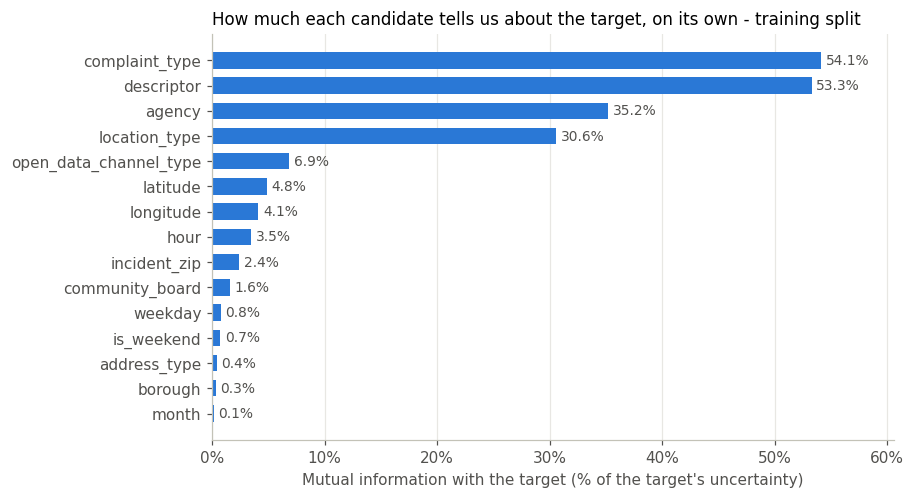

In [8]:
plot = mi["mi_pct_of_target"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.barh(plot.index, plot.values, color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in plot.values], color=INK, fontsize=9, padding=3)
ax.set_xlim(0, plot.max() * 1.12)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("Mutual information with the target (% of the target's uncertainty)")
ax.set_title("How much each candidate tells us about the target, on its own - training split", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "04_mutual_information.png")
plt.show()

**Reading it.** What the request is *about* dominates: `complaint_type` and `descriptor` each remove more than half of the uncertainty, followed by `agency` and `location_type`. Where and when the request was filed matter far less on their own. The shuffled-target column stays near zero even for the columns with hundreds of values, so the large numbers are real and not an effect of having many categories.

### 6.2 Permutation importance and tree importance

A quick `XGBClassifier` is trained on the training split with all 15 candidates.

- **Permutation importance (validation split).** Shuffle one input column, so it no longer matches its row, and see how much the score drops. A big drop means the model relies on that column. The shuffle is done on the raw input columns, so shuffling `created_date` shuffles all four time features together. Each column is shuffled 5 times.
- **Tree importance.** How much the model's own splits on a feature improved its fit ("gain"), added up over that feature's one-hot columns and shown as a share of the total. It comes from the training data and tends to favour features with many categories.

Both methods share one weakness: when two features carry the same information, the model picks one and the other looks useless (or the credit is split). That is why redundancy is checked next.

In [9]:
def quick_model():
    return XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method="hist",
                         random_state=SEED, n_jobs=-1)

def fit_and_score(features, validation=None):
    """Train the quick model on the training split, score it on the validation split."""
    validation = val if validation is None else validation
    pipe = ft.build_pipeline(quick_model(), features).fit(train[ft.RAW_INPUT_COLUMNS], y_train)
    proba = pipe.predict_proba(validation[ft.RAW_INPUT_COLUMNS])[:, 1]
    return pipe, {"roc_auc": roc_auc_score(y_val, proba), "macro_f1": f1_score(y_val, proba >= 0.5, average="macro")}

start = time.time()
full_pipe, full_scores = fit_and_score(ft.CANDIDATE_FEATURES)
print(f"Quick XGBoost, all 15 candidates: validation ROC-AUC {full_scores['roc_auc']:.4f}, macro F1 {full_scores['macro_f1']:.4f} "
      f"(trained in {time.time() - start:.0f} s)")
print(f"For comparison, always answering 'within 7 days' gives macro F1 {f1_score(y_val, np.ones(len(y_val)), average='macro'):.4f} and ROC-AUC 0.5")

Quick XGBoost, all 15 candidates: validation ROC-AUC 0.9436, macro F1 0.8278 (trained in 8 s)
For comparison, always answering 'within 7 days' gives macro F1 0.4542 and ROC-AUC 0.5


In [10]:
perm = permutation_importance(full_pipe, val[ft.RAW_INPUT_COLUMNS], y_val, scoring=["roc_auc", "f1_macro"],
                              n_repeats=5, random_state=SEED)
permutation = pd.DataFrame({"roc_auc_drop": perm["roc_auc"].importances_mean,
                            "roc_auc_drop_std": perm["roc_auc"].importances_std,
                            "macro_f1_drop": perm["f1_macro"].importances_mean},
                           index=ft.RAW_INPUT_COLUMNS).sort_values("roc_auc_drop", ascending=False)
permutation = permutation.rename(index={"created_date": "created_date (4 time features)"})

# Tree importance: add up the one-hot columns that belong to each feature
names = full_pipe["encode"].get_feature_names_out()
gain = pd.Series(full_pipe["model"].feature_importances_, index=names)
def owner(encoded_name):
    rest = encoded_name.split("__", 1)[1].replace("missingindicator_", "")
    return next(f for f in sorted(ft.CANDIDATE_FEATURES, key=len, reverse=True) if rest.startswith(f))
tree = gain.groupby(owner).sum().sort_values(ascending=False).rename("tree_gain_share")
columns_per_feature = pd.Series(names).map(owner).value_counts().rename("encoded_columns")

display(permutation.style.format("{:.4f}"))
display(pd.concat([tree, columns_per_feature], axis=1).style.format({"tree_gain_share": "{:.1%}", "encoded_columns": "{:,}"}))

,roc_auc_drop,roc_auc_drop_std,macro_f1_drop
agency,0.3160,0.0041,0.1988
complaint_type,0.1594,0.0024,0.1951
descriptor,0.0048,0.0004,0.0166
location_type,0.0041,0.0003,0.0490
borough,0.0011,0.0002,0.0008
created_date (4 time features),0.0004,0.0002,0.0006
latitude,0.0003,0.0000,-0.0000
longitude,0.0001,0.0000,0.0004
address_type,0.0000,0.0001,0.0008
community_board,-0.0000,0.0000,0.0003


,tree_gain_share,encoded_columns
agency,46.9%,14
complaint_type,34.3%,103
descriptor,11.7%,231
location_type,4.2%,34
incident_zip,1.3%,176
community_board,0.6%,66
borough,0.4%,6
address_type,0.4%,7
open_data_channel_type,0.1%,5
month,0.0%,1


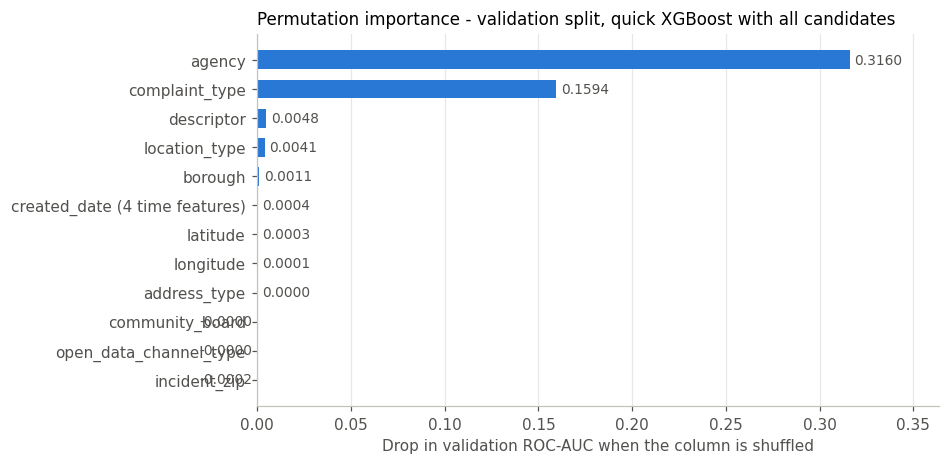

In [11]:
plot = permutation["roc_auc_drop"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.4))
bars = ax.barh(plot.index, plot.values, color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in plot.values], color=INK, fontsize=9, padding=3)
ax.set_xlim(min(plot.min(), 0) * 1.5, plot.max() * 1.15)
ax.set_xlabel("Drop in validation ROC-AUC when the column is shuffled")
ax.set_title("Permutation importance - validation split, quick XGBoost with all candidates", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "04_permutation_importance.png")
plt.show()

**Reading it.** The model leans almost entirely on `agency` and `complaint_type`; `descriptor` and `location_type` add a little, and everything else is close to zero. That does **not** mean the other columns are useless: `agency`, `complaint_type` and `descriptor` largely say the same thing, so the model can take the information from any of them. The next two checks untangle this.

### 6.3 Redundancy

Two features are redundant when one can be worked out from the other. The measure used here is simple: *if I know A, how often can I name B correctly by always guessing the most common B for that A?* 100% means A fully determines B.

In [12]:
def determines(a, b):
    """Share of training rows where b is the most common b for the row's a."""
    return train.groupby(a)[b].agg(lambda s: s.value_counts().iloc[0]).sum() / len(train)

pairs = [("incident_zip", "borough"), ("community_board", "borough"), ("incident_zip", "community_board"),
         ("community_board", "incident_zip"), ("borough", "incident_zip"),
         ("complaint_type", "agency"), ("agency", "complaint_type"), ("descriptor", "complaint_type")]
redundancy = pd.DataFrame([{"if_we_know": a, "we_can_name": b, "correct": determines(a, b),
                            "values_of_known": train[a].nunique(), "values_of_named": train[b].nunique()} for a, b in pairs])
display(redundancy.style.format({"correct": "{:.1%}"}).hide(axis="index"))

multi = train.groupby("complaint_type")["agency"].nunique()
print("Complaint types handled by more than one agency in the training split:", sorted(multi[multi > 1].index))

if_we_know,we_can_name,correct,values_of_known,values_of_named
incident_zip,borough,99.3%,176,6
community_board,borough,99.1%,66,6
incident_zip,community_board,80.3%,176,66
community_board,incident_zip,41.8%,66,176
borough,incident_zip,7.7%,6,176
complaint_type,agency,99.0%,103,14
agency,complaint_type,34.2%,14,103
descriptor,complaint_type,86.6%,231,103


Complaint types handled by more than one agency in the training split: ['ASBESTOS', 'ELEVATOR', 'ENCAMPMENT', 'GRAFFITI', 'HIGHWAY CONDITION', 'Other', 'PLUMBING']


**Reading it.**

- **Location.** The ZIP code gives the borough 99% of the time, and so does the community board. ZIP code and community board are two ways of cutting the city into small areas, and the ZIP code names the community board 4 times in 5. So `borough` and `community_board` add little once `incident_zip` (and the coordinates) are present.
- **Agency.** The complaint type gives the agency 99% of the time: each kind of complaint is routed to one agency. The reverse is not true (an agency handles many complaint types). So `agency` is almost a coarser copy of `complaint_type`. The exceptions are a few complaint types shared by two agencies, and the rare types grouped as `Other`.

### 6.4 Drop-one-group test

The most direct test: train the quick model **without** one group of features and see what happens to the validation scores. If the scores do not move, the model does not need that group, whatever the other measures say.

Every row is a model trained again from scratch on the training split and scored on the validation split. Negative numbers mean the score got worse without the group, so the group was helping.

Each row is a single trained model, so very small differences (about 0.001 or less) are not reliable and are treated here as "no clear difference".

In [13]:
groups = {name: [name] for name in ft.CATEGORICAL_CANDIDATES}
groups["latitude + longitude"] = ft.COORDINATE_FEATURES
groups["time features (4)"] = ft.TIME_FEATURES

rows = []
for name, columns in groups.items():
    _, scores = fit_and_score([f for f in ft.CANDIDATE_FEATURES if f not in columns])
    rows.append({"group_removed": name, "roc_auc": scores["roc_auc"], "macro_f1": scores["macro_f1"],
                 "roc_auc_change": scores["roc_auc"] - full_scores["roc_auc"],
                 "macro_f1_change": scores["macro_f1"] - full_scores["macro_f1"]})
drop_one = pd.DataFrame(rows).set_index("group_removed").sort_values("macro_f1_change")

print(f"All 15 candidates: ROC-AUC {full_scores['roc_auc']:.4f}, macro F1 {full_scores['macro_f1']:.4f}")
asked = ["agency", "community_board", "address_type", "latitude + longitude", "time features (4)"]
print("\nThe five groups in question:")
display(drop_one.loc[asked].style.format("{:.4f}").format("{:+.4f}", subset=["roc_auc_change", "macro_f1_change"]))
print("Every group, for completeness:")
display(drop_one.style.format("{:.4f}").format("{:+.4f}", subset=["roc_auc_change", "macro_f1_change"]))

All 15 candidates: ROC-AUC 0.9436, macro F1 0.8278

The five groups in question:


,roc_auc,macro_f1,roc_auc_change,macro_f1_change
group_removed,,,,
agency,0.9419,0.8200,-0.0017,-0.0078
community_board,0.9437,0.8276,+0.0002,-0.0003
address_type,0.9434,0.8271,-0.0002,-0.0007
latitude + longitude,0.9435,0.8268,-0.0001,-0.0010
time features (4),0.9434,0.8246,-0.0002,-0.0032


Every group, for completeness:


,roc_auc,macro_f1,roc_auc_change,macro_f1_change
group_removed,,,,
descriptor,0.9401,0.8152,-0.0034,-0.0126
agency,0.9419,0.8200,-0.0017,-0.0078
complaint_type,0.9434,0.8234,-0.0002,-0.0045
time features (4),0.9434,0.8246,-0.0002,-0.0032
open_data_channel_type,0.9434,0.8260,-0.0001,-0.0018
location_type,0.9439,0.8266,+0.0003,-0.0012
latitude + longitude,0.9435,0.8268,-0.0001,-0.0010
address_type,0.9434,0.8271,-0.0002,-0.0007
incident_zip,0.9436,0.8276,-0.0000,-0.0003


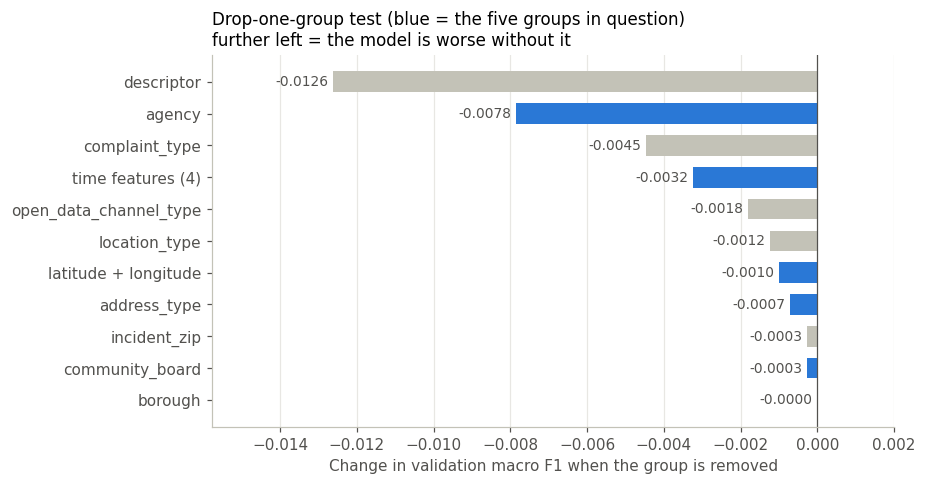

In [14]:
plot = drop_one["macro_f1_change"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.4))
bars = ax.barh(plot.index, plot.values, color=[BLUE if name in asked else GREY for name in plot.index], height=0.65)
ax.bar_label(bars, labels=[f"{v:+.4f}" for v in plot.values], color=INK, fontsize=9, padding=3)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlim(plot.min() * 1.25, max(plot.max(), 0) + 0.002)
ax.set_xlabel("Change in validation macro F1 when the group is removed")
ax.set_title("Drop-one-group test (blue = the five groups in question)\nfurther left = the model is worse without it",
             loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "04_drop_one_group.png")
plt.show()

**Reading it.**

- **`community_board`** and **`address_type`**: removing them changes nothing measurable. They are also the two columns a person filing a request cannot give: the community board is a district number, and the address type is a label the city's own address-matching software assigns.
- **`latitude + longitude`** and the **time features**: small effects, but the caller can always supply them (a location and the time of filing), so there is no reason to drop them.
- **`agency`**: the only doubtful group with a real effect. Even though the complaint type gives the agency 99% of the time, the model is a little worse without it.

### 6.5 A closer look at `agency`

`agency` helps, but a person filing a request does not know which agency will handle it, and the API request format has no agency field. So the fair question is: **what does the model score when the agency is not handed to it?** Three ways of serving a model trained *with* agency are compared with a model trained *without* it.

In [15]:
without_extras = [f for f in ft.CANDIDATE_FEATURES if f not in ("community_board", "address_type")]
with_agency, s_true = fit_and_score(without_extras)

def score_on(validation):
    proba = with_agency.predict_proba(validation[ft.RAW_INPUT_COLUMNS])[:, 1]
    return {"roc_auc": roc_auc_score(y_val, proba), "macro_f1": f1_score(y_val, proba >= 0.5, average="macro")}

# Agency worked out from the complaint type, using a lookup learned on the training split
lookup = train.groupby("complaint_type")["agency"].agg(lambda s: s.value_counts().index[0])
val_lookup = val.assign(agency=val["complaint_type"].map(lookup))
val_missing = val.assign(agency=None)
_, s_without = fit_and_score([f for f in without_extras if f != "agency"])

agency_test = pd.DataFrame({
    "Trained with agency; true agency supplied": s_true,
    "Trained with agency; agency guessed from complaint type": score_on(val_lookup),
    "Trained with agency; agency left empty": score_on(val_missing),
    "Trained without agency": s_without,
}).T
display(agency_test.style.format("{:.4f}"))
print(f"The guessed agency equals the true agency for {(val_lookup['agency'] == val['agency']).mean():.1%} of validation rows.")

,roc_auc,macro_f1
Trained with agency; true agency supplied,0.9439,0.8276
Trained with agency; agency guessed from complaint type,0.9398,0.8243
Trained with agency; agency left empty,0.8523,0.7424
Trained without agency,0.9421,0.8191


The guessed agency equals the true agency for 99.1% of validation rows.


**Reading it.**

- With the **true** agency the model is slightly better than a model without the feature.
- If the agency is **left empty**, the model that was trained with it becomes much worse, because it has learned to lean on a value that is no longer there.
- If the agency is **guessed** from the complaint type, the result is mixed: ROC-AUC is lower than for the model without agency and macro F1 is a little higher. The guess adds nothing the model could not already get from `complaint_type`.

So the clear benefit exists only when the real agency is supplied, and a person filing a request cannot supply it.

**Decision (confirmed by the student): drop `agency`.** The API keeps the request format of the project specification, and there is no risk of poor predictions when a caller leaves the field out. The cost is small, as the last row shows.

## 7. Final feature list

One row per candidate: the decision, the reason, the evidence from section 6, and whether a person filing a request could give this value to the API.

Evidence columns: `mi_pct` is mutual information (6.1); `perm_auc_drop` is permutation importance (6.2); `drop_f1_change` is the change in validation macro F1 when the feature's group is removed (6.4). For latitude/longitude and the time features, the last two are measured for the group as a whole.

In [16]:
decisions = {
    "complaint_type": ("KEEP", "Strongest single feature: what the request is about", "Yes - required field"),
    "descriptor": ("KEEP", "Largest loss when removed; adds detail within a complaint type", "Yes - optional field"),
    "location_type": ("KEEP", "High mutual information; largest permutation effect on macro F1 after agency and complaint_type", "Yes - optional field"),
    "open_data_channel_type": ("KEEP", "Small but real effect on macro F1; always known at filing", "Yes - required field (PHONE, ONLINE, MOBILE)"),
    "borough": ("KEEP", "Weak, mostly repeated by ZIP code; kept as the simplest location field, and it is required by the API", "Yes - required field"),
    "incident_zip": ("KEEP", "Weak in this test because coordinates and borough carry the same information; kept as the location a caller is most likely to know", "Yes - optional field"),
    "latitude": ("KEEP", "Small effect; gives location when no ZIP code is known", "Yes - optional (from a map pin or phone location)"),
    "longitude": ("KEEP", "Small effect; gives location when no ZIP code is known", "Yes - optional (from a map pin or phone location)"),
    "hour": ("KEEP", "Time features together have a clear effect on macro F1", "Yes - derived by the server from created_at"),
    "weekday": ("KEEP", "Time features together have a clear effect on macro F1", "Yes - derived by the server from created_at"),
    "month": ("KEEP", "Weakest time feature on its own; kept with the group (seasonal work such as heating)", "Yes - derived by the server from created_at"),
    "is_weekend": ("KEEP", "Time features together have a clear effect on macro F1", "Yes - derived by the server from created_at"),
    "agency": ("DROP", "Helps only when the true agency is supplied (6.5); 99% determined by complaint_type; the caller cannot supply it",
               "No - assigned by the city's routing. If kept, it would have to be an extra API field filled in by 311 staff"),
    "address_type": ("DROP", "No measurable effect when removed", "No - a label assigned by the city's address-matching software"),
    "community_board": ("DROP", "No measurable effect when removed; 99% of its borough information and most of its area information is in the ZIP code",
                        "No - a district number callers do not know. If kept, the server would need a map lookup from the coordinates"),
}
assert set(decisions) == set(ft.CANDIDATE_FEATURES)

def group_of(feature):
    if feature in ft.COORDINATE_FEATURES: return "latitude + longitude"
    if feature in ft.TIME_FEATURES: return "time features (4)"
    return feature
def permutation_row(feature):
    return "created_date (4 time features)" if feature in ft.TIME_FEATURES else feature

final_table = pd.DataFrame([{
    "feature": f, "decision": decisions[f][0], "reason": decisions[f][1],
    "mi_pct": mi.loc[f, "mi_pct_of_target"],
    "perm_auc_drop": permutation.loc[permutation_row(f), "roc_auc_drop"],
    "drop_f1_change": drop_one.loc[group_of(f), "macro_f1_change"],
    "drop_auc_change": drop_one.loc[group_of(f), "roc_auc_change"],
    "can_the_caller_supply_it": decisions[f][2],
} for f in decisions]).set_index("feature")

with pd.option_context("display.max_colwidth", None):
    display(final_table.style.format({"mi_pct": "{:.2f}%", "perm_auc_drop": "{:.4f}", "drop_f1_change": "{:+.4f}",
                                      "drop_auc_change": "{:+.4f}"}).set_properties(**{"text-align": "left"}))
final_table.to_csv("../reports/feature_selection.csv")
print("Saved ../reports/feature_selection.csv")

,decision,reason,mi_pct,perm_auc_drop,drop_f1_change,drop_auc_change,can_the_caller_supply_it
feature,,,,,,,
complaint_type,KEEP,Strongest single feature: what the request is about,54.11%,0.1594,-0.0045,-0.0002,Yes - required field
descriptor,KEEP,Largest loss when removed; adds detail within a complaint type,53.30%,0.0048,-0.0126,-0.0034,Yes - optional field
location_type,KEEP,High mutual information; largest permutation effect on macro F1 after agency and complaint_type,30.57%,0.0041,-0.0012,+0.0003,Yes - optional field
open_data_channel_type,KEEP,Small but real effect on macro F1; always known at filing,6.86%,-0.0000,-0.0018,-0.0001,"Yes - required field (PHONE, ONLINE, MOBILE)"
borough,KEEP,"Weak, mostly repeated by ZIP code; kept as the simplest location field, and it is required by the API",0.32%,0.0011,-0.0000,-0.0002,Yes - required field
incident_zip,KEEP,Weak in this test because coordinates and borough carry the same information; kept as the location a caller is most likely to know,2.41%,-0.0002,-0.0003,-0.0000,Yes - optional field
latitude,KEEP,Small effect; gives location when no ZIP code is known,4.84%,0.0003,-0.0010,-0.0001,Yes - optional (from a map pin or phone location)
longitude,KEEP,Small effect; gives location when no ZIP code is known,4.12%,0.0001,-0.0010,-0.0001,Yes - optional (from a map pin or phone location)
hour,KEEP,Time features together have a clear effect on macro F1,3.47%,0.0004,-0.0032,-0.0002,Yes - derived by the server from created_at


Saved ../reports/feature_selection.csv


In [17]:
kept = [f for f in ft.CANDIDATE_FEATURES if decisions[f][0] == "KEEP"]
assert kept == ft.FINAL_FEATURES, "src/features.py FINAL_FEATURES does not match this table"
ft.assert_no_excluded(kept)

print(f"Final features ({len(kept)}):")
for group, members in [("text", ft.CATEGORICAL_CANDIDATES), ("location", ft.COORDINATE_FEATURES), ("time", ft.TIME_FEATURES)]:
    print(f"  {group:9s}: {[f for f in kept if f in members]}")
print("Dropped:", [f for f in ft.CANDIDATE_FEATURES if f not in kept])

# The final preprocessing pipeline (no model yet), fitted on the training split only
final_features = ft.build_pipeline()
X_train = final_features.fit_transform(train[ft.RAW_INPUT_COLUMNS])
X_val = final_features.transform(val[ft.RAW_INPUT_COLUMNS])

encoded = pd.Series(final_features["encode"].get_feature_names_out()).str.split("__").str[0].value_counts()
print(f"\nPipeline output shape: train {X_train.shape}, validation {X_val.shape}  ({type(X_train).__name__}, sparse)")
print(f"Encoded columns: {encoded['cat']} one-hot (text) + {encoded['coord']} coordinates (2 values, 2 'was missing' flags) + {encoded['time']} time")

_, final_scores = fit_and_score(kept)
comparison = pd.DataFrame({"All 15 candidates": full_scores, f"Final {len(kept)} features": final_scores}).T
comparison["encoded_columns"] = [X_train_all.shape[1], X_train.shape[1]]
display(comparison.style.format({"roc_auc": "{:.4f}", "macro_f1": "{:.4f}"}))

Final features (12):
  text     : ['complaint_type', 'descriptor', 'location_type', 'borough', 'incident_zip', 'open_data_channel_type']
  location : ['latitude', 'longitude']
  time     : ['hour', 'weekday', 'month', 'is_weekend']
Dropped: ['agency', 'address_type', 'community_board']



Pipeline output shape: train (139206, 563), validation (29830, 563)  (csr_matrix, sparse)
Encoded columns: 555 one-hot (text) + 4 coordinates (2 values, 2 'was missing' flags) + 4 time


,roc_auc,macro_f1,encoded_columns
All 15 candidates,0.9436,0.8278,650
Final 12 features,0.9421,0.8191,563


**Summary.**

- The final model uses **12 features**: six text fields (`complaint_type`, `descriptor`, `location_type`, `borough`, `incident_zip`, `open_data_channel_type`), `latitude` and `longitude`, and four time features made from the filing time.
- Three candidates are dropped: `agency`, `address_type` and `community_board`. None of them can be given by a person filing a request. Two of them add nothing measurable; `agency` adds a little, but only when the true agency is known.
- Every kept feature is something the API caller sends or the server works out from `created_at`, so the API request format in the project specification does not change.
- The pipeline's cleaning step was shown to reproduce the cleaned file exactly, and to cope with unseen categories, missing values and bad coordinates.
- The test split was not used.

The scores in this notebook come from a quick, untuned model and are for comparing feature sets only. Phase 5 compares the real models.